In [ ]:
import pandas as pd
import os
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
import nltk

try:
    stopwords.words('english')
except LookupError:
    nltk.download('stopwords')
    nltk.download('wordnet')
    nltk.download('punkt')

RAW_DATA_PATH = '/kaggle/input/reddit-mental-health-dataset/Original Reddit Data/raw data'
OUTPUT_FOLDER = '/kaggle/working/'
OUTPUT_FILENAME = os.path.join(OUTPUT_FOLDER, 'cleaned_labelled_raw_data.csv')

# --- Text Cleaning Function ---
def clean_text(text):
    if not isinstance(text, str):
        return ""
    lemmatizer = WordNetLemmatizer()
    stop_words = set(stopwords.words('english'))
    text = text.lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'[^a-z\s]', '', text)
    tokens = word_tokenize(text)
    cleaned_tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words and len(word) > 2]
    return " ".join(cleaned_tokens)

# --- Main Processing Logic ---
def main():
    print("Starting data processing...")
    if not os.path.exists(OUTPUT_FOLDER):
        os.makedirs(OUTPUT_FOLDER)

    all_data = []
    label_mapping = {
        'ani': 'anxiety', 'dep': 'depression', 'lon': 'lonely',
        'mhj': 'mentalhealth', 'swj': 'suicidewatch'
    }

    for root, _, files in os.walk(RAW_DATA_PATH):
        for filename in files:
            if filename.endswith('.csv'):
                file_path = os.path.join(root, filename)
                prefix = filename[:3].lower()
                label = label_mapping.get(prefix, 'unknown')
                print(f"Processing {file_path} with label '{label}'...")

                try:
                    df = pd.read_csv(file_path)
                    
                    if 'selftext' in df.columns:
                        
                        for text in df['selftext']:
                            all_data.append({'text': text, 'label': label})
                    else:
                        print(f"  [Warning] Column 'selftext' not found in {filename}. Skipping.")

                except Exception as e:
                    print(f"  [Error] Could not process {filename}. Reason: {e}")

    print("\nCombining all data into a single DataFrame...")
    master_df = pd.DataFrame(all_data)
    master_df.dropna(subset=['text'], inplace=True)
    master_df.reset_index(drop=True, inplace=True)
    print(f"Total posts collected: {len(master_df)}")

    print("Cleaning and preprocessing text... (This may take a while)")
    master_df['cleaned_text'] = master_df['text'].apply(clean_text)

    print(f"Saving cleaned data to {OUTPUT_FILENAME}...")
    master_df.to_csv(OUTPUT_FILENAME, index=False)
    
    print("\nProcessing complete!")
    print(f"Your cleaned file is ready at '{OUTPUT_FILENAME}'")

main()

In [ ]:
#Removing noisy labels
import pandas as pd

# Define the path to your data file
file_path = '/kaggle/working/cleaned_labelled_raw_data.csv'

# Step 1: Load the Data
print(f"Loading data from {file_path}...")
df = pd.read_csv(file_path)
print(f"Original number of posts: {len(df)}")


# Step 2: Filter out the 'unknown' category
print("\nFiltering out rows with the 'unknown' label...")
df_clean = df[df['label'] != 'unknown'].copy()
print(f"Number of posts after filtering: {len(df_clean)}")


# Step 3: Save the cleaned data back to the same file
print(f"\nSaving the cleaned data back to {file_path}...")
df_clean.to_csv(file_path, index=False)

print("\nFile has been successfully updated.")

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load your cleaned dataset
df = pd.read_csv('/kaggle/input/processed-data/cleaned_labelled_raw_data (2).csv')

# Display the first 5 rows
print("First 5 rows of the dataset:")
print(df.head())

# Display a summary of the dataset (columns, data types, non-null counts)
print("\nDataset Info:")
df.info()

First 5 rows of the dataset:
                                                text       label  \
0                                          [removed]  depression   
1  I’ve been in the worst rut the past several we...  depression   
2  You try hard to start a fire. It takes a long ...  depression   
3  this year has been tough for me. For the past ...  depression   
4  I'm almost 25 and it has become clear to me th...  depression   

                                        cleaned_text  
0                                            removed  
1  ive worst rut past several week mostly try con...  
2  try hard start fire take long time lot effort ...  
3  year tough past month done nothing avoid playi...  
4  almost become clear want end life around becam...  

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1024932 entries, 0 to 1024931
Data columns (total 3 columns):
 #   Column        Non-Null Count    Dtype 
---  ------        --------------    ----- 
 0   text        


Class Distribution:
label
depression      613073
lonely          153823
suicidewatch    115397
mentalhealth     81249
anxiety          61390
Name: count, dtype: int64


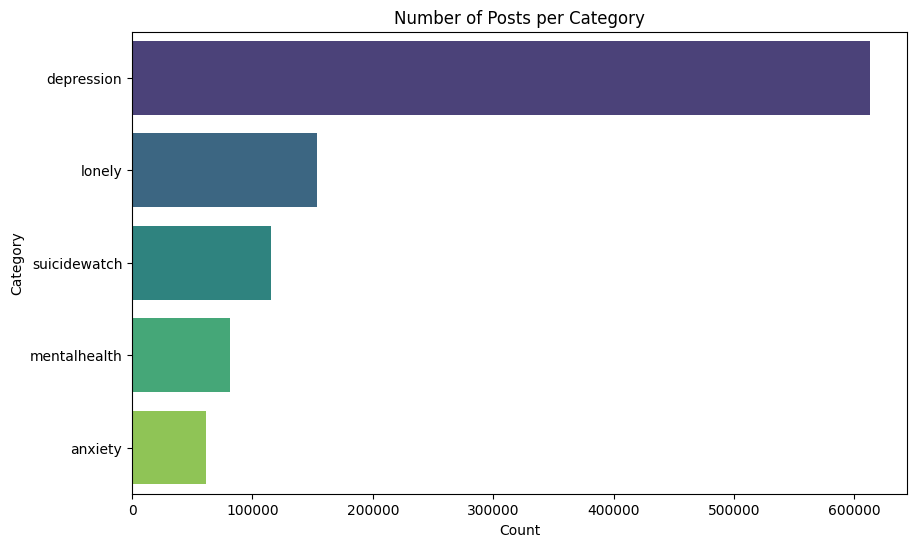

In [3]:
# Count the number of posts in each category
print("\nClass Distribution:")
print(df['label'].value_counts())

# Visualize the distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df, y='label', order = df['label'].value_counts().index, palette='viridis')
plt.title('Number of Posts per Category')
plt.xlabel('Count')
plt.ylabel('Category')
plt.show()

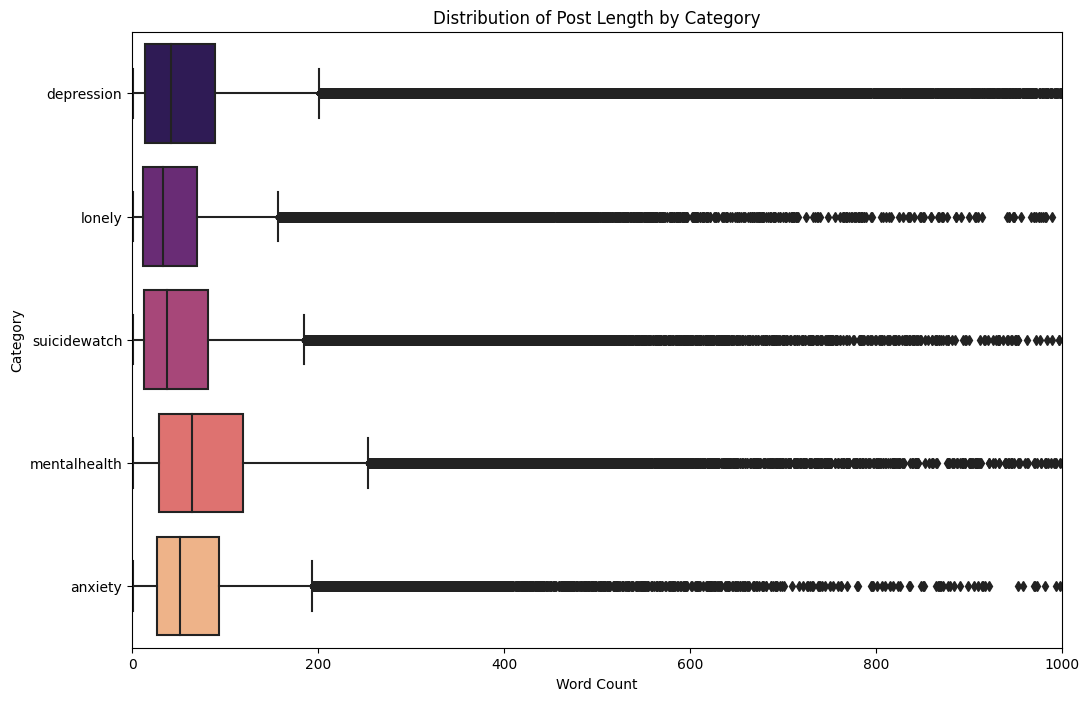

In [4]:
# Calculate the word count for each cleaned post
df['word_count'] = df['cleaned_text'].str.split().str.len()

# Plot the distribution of word counts for each category
plt.figure(figsize=(12, 8))
sns.boxplot(data=df, x='word_count', y='label', palette='magma')
plt.title('Distribution of Post Length by Category')
plt.xlabel('Word Count')
plt.ylabel('Category')
plt.xlim(0, 1000) # Limiting x-axis for better readability
plt.show()

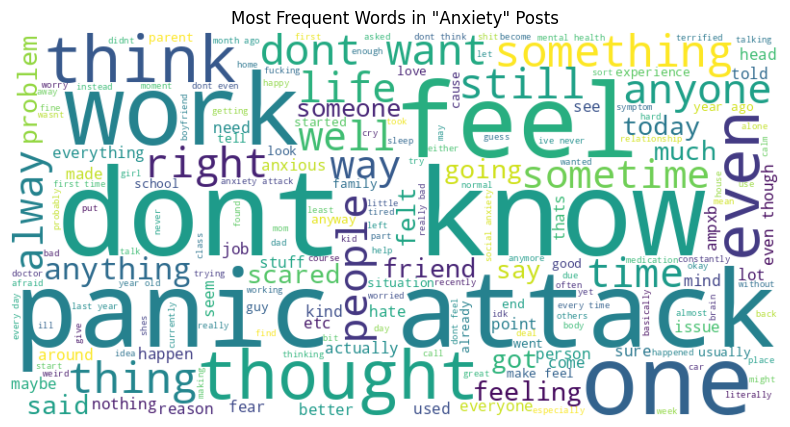

In [5]:
from wordcloud import WordCloud

# Let's generate a word cloud for the 'anxiety' category
anxiety_text = ' '.join(df[df['label'] == 'anxiety']['cleaned_text'].dropna())

wordcloud = WordCloud(width=800, height=400, background_color='white').generate(anxiety_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Most Frequent Words in "Anxiety" Posts')
plt.show()

In [3]:
from sklearn.model_selection import train_test_split

# Define your features (X) and target (y)
X = df['cleaned_text'].fillna('') # Use fillna('') to handle any potential empty text after cleaning
y = df['label']

# Split the data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training data shape: {X_train.shape}")
print(f"Testing data shape: {X_test.shape}")

Training data shape: (819945,)
Testing data shape: (204987,)


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize the TF-IDF Vectorizer
tfidf = TfidfVectorizer(max_features=5000) # Limit to the top 5000 features (words)

# Fit the vectorizer on the training data and transform it
X_train_tfidf = tfidf.fit_transform(X_train)

# Only transform the test data using the already-fitted vectorizer
X_test_tfidf = tfidf.transform(X_test)

print(f"Shape of TF-IDF matrix for training data: {X_train_tfidf.shape}")
print(f"Shape of TF-IDF matrix for testing data: {X_test_tfidf.shape}")

Shape of TF-IDF matrix for training data: (819945, 5000)
Shape of TF-IDF matrix for testing data: (204987, 5000)


Model training complete!

Classification Report:
              precision    recall  f1-score   support

     anxiety       0.74      0.58      0.65     12278
  depression       0.70      0.91      0.79    122615
      lonely       0.69      0.52      0.59     30765
mentalhealth       0.58      0.20      0.29     16250
suicidewatch       0.51      0.15      0.23     23079

    accuracy                           0.69    204987
   macro avg       0.64      0.47      0.51    204987
weighted avg       0.67      0.69      0.65    204987


Confusion Matrix:


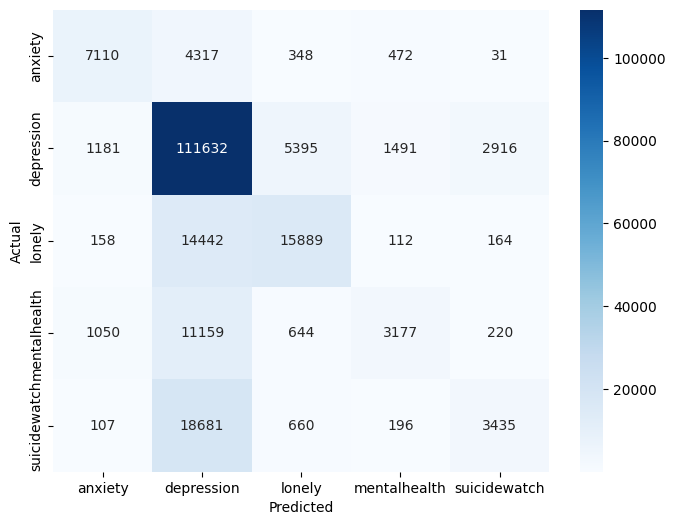

In [14]:
# Correct imports for Logistic Regression and evaluation
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Initialize and train the Logistic Regression model
LR_model = LogisticRegression(max_iter=1000)
LR_model.fit(X_train_tfidf, y_train)

print("Model training complete!")

# Make predictions on the test data
y_pred = LR_model.predict(X_test_tfidf)

# Print the classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Generate and plot the confusion matrix
print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=LR_model.classes_, yticklabels=LR_model.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Naive Bayes model trained successfully!

--- Multinomial Naive Bayes Classification Report ---
              precision    recall  f1-score   support

     anxiety       0.79      0.22      0.35     12278
  depression       0.63      0.98      0.77    122615
      lonely       0.76      0.28      0.41     30765
mentalhealth       0.66      0.03      0.06     16250
suicidewatch       0.67      0.01      0.02     23079

    accuracy                           0.64    204987
   macro avg       0.70      0.30      0.32    204987
weighted avg       0.67      0.64      0.55    204987


Confusion Matrix:


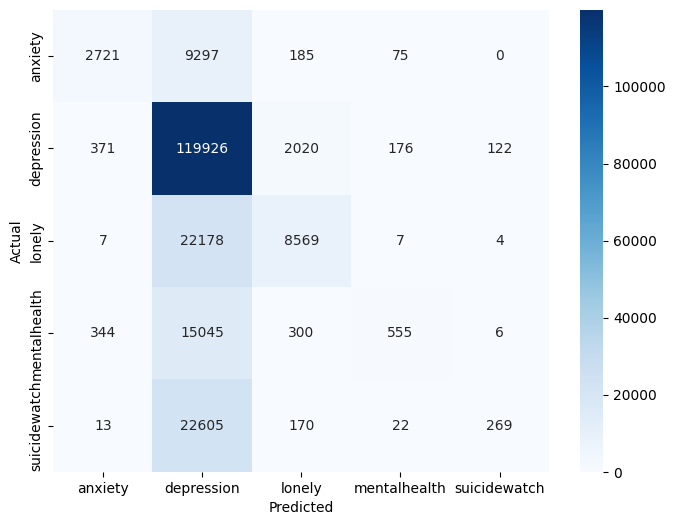

In [15]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Initialize and train the Naive Bayes model
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

print("Naive Bayes model trained successfully!")

# 2. Make predictions and evaluate
y_pred_nb = nb_model.predict(X_test_tfidf)

print("\n--- Multinomial Naive Bayes Classification Report ---")
print(classification_report(y_test, y_pred_nb))

# Generate and plot the confusion matrix
print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred_nb)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=nb_model.classes_, yticklabels=nb_model.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Support Vector Machine model trained successfully!

--- Support Vector Machine (LinearSVC) Report ---
              precision    recall  f1-score   support

     anxiety       0.73      0.57      0.64     12278
  depression       0.69      0.93      0.79    122615
      lonely       0.68      0.50      0.58     30765
mentalhealth       0.64      0.13      0.21     16250
suicidewatch       0.53      0.09      0.16     23079

    accuracy                           0.69    204987
   macro avg       0.65      0.44      0.48    204987
weighted avg       0.67      0.69      0.63    204987


Confusion Matrix:


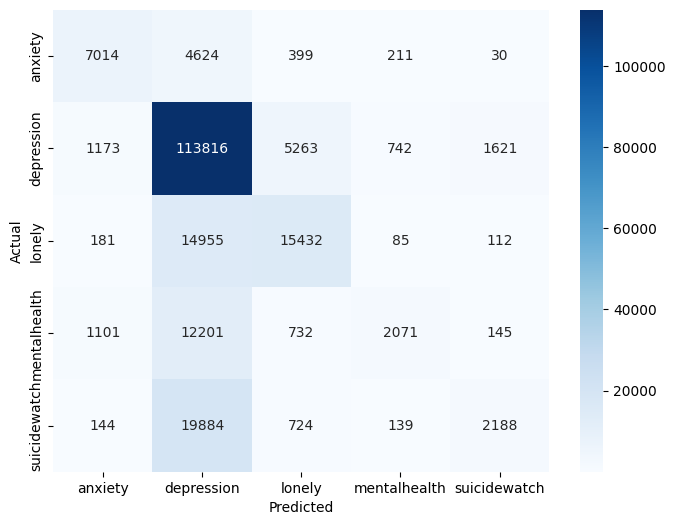

In [16]:
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Initialize and train the LinearSVC model
svm_model = LinearSVC(random_state=42, dual=False) # dual=False is a performance recommendation
svm_model.fit(X_train_tfidf, y_train)

print("Support Vector Machine model trained successfully!")

# 2. Make predictions and evaluate
y_pred_svm = svm_model.predict(X_test_tfidf)

print("\n--- Support Vector Machine (LinearSVC) Report ---")
print(classification_report(y_test, y_pred_svm))

# Generate and plot the confusion matrix
print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred_svm)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=svm_model.classes_, yticklabels=svm_model.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Random Forest model trained successfully!

--- Random Forest Classification Report ---
              precision    recall  f1-score   support

     anxiety       0.77      0.39      0.52     12278
  depression       0.66      0.96      0.78    122615
      lonely       0.70      0.38      0.49     30765
mentalhealth       0.57      0.04      0.07     16250
suicidewatch       0.42      0.03      0.05     23079

    accuracy                           0.66    204987
   macro avg       0.62      0.36      0.38    204987
weighted avg       0.64      0.66      0.58    204987


Confusion Matrix:


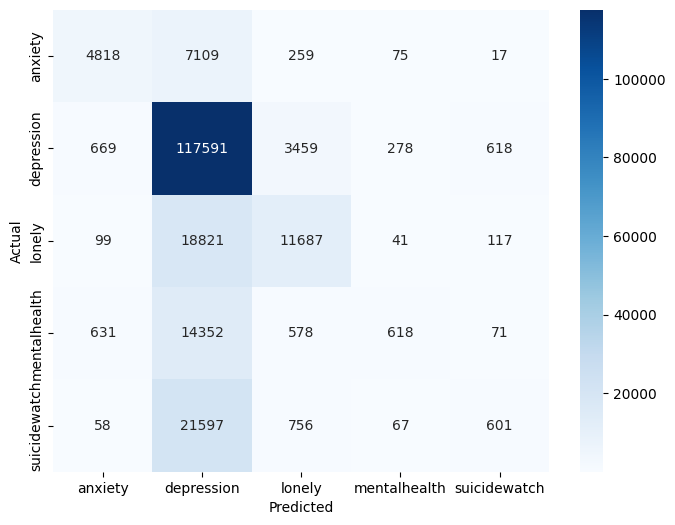

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Initialize and train the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=50,       
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_tfidf, y_train)
print("Random Forest model trained successfully!")

# 2. Make predictions and evaluate
y_pred_rf = rf_model.predict(X_test_tfidf)

print("\n--- Random Forest Classification Report ---")
print(classification_report(y_test, y_pred_rf))

# Generate and plot the confusion matrix
print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=rf_model.classes_, yticklabels=rf_model.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [5]:
import lightgbm as lgb
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Initialize and train the LightGBM model
lgb_model = lgb.LGBMClassifier(random_state=42)
lgb_model.fit(X_train_tfidf, y_train)

print("LightGBM model trained successfully!")

# 2. Make predictions and evaluate
y_pred_lgb = lgb_model.predict(X_test_tfidf)

print("\n--- LightGBM Classification Report ---")
print(classification_report(y_test, y_pred_lgb))

# Generate and plot the confusion matrix
print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred_lgb)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=lgb_model.classes_, yticklabels=lgb_model.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 39.107571 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 787834
[LightGBM] [Info] Number of data points in the train set: 819945, number of used features: 4998
[LightGBM] [Info] Start training from score -2.815134
[LightGBM] [Info] Start training from score -0.513898
[LightGBM] [Info] Start training from score -1.896581
[LightGBM] [Info] Start training from score -2.534865
[LightGBM] [Info] Start training from score -2.183998
LightGBM model trained successfully!

--- LightGBM Classification Report ---
              precision    recall  f1-score   support

     anxiety       0.72      0.57      0.64     12278
  depression       0.69      0.92      0.79    122615
      lonely       0.68      0.49      0.57     30765
mentalhealth       0.61      0.14      0.23     16250
suicidewatch       0.53      0.10      0.16     23079

    accuracy                    

NameError: name 'confusion_matrix' is not defined


--- LightGBM Classification Report ---
              precision    recall  f1-score   support

     anxiety       0.72      0.57      0.64     12278
  depression       0.69      0.92      0.79    122615
      lonely       0.68      0.49      0.57     30765
mentalhealth       0.61      0.14      0.23     16250
suicidewatch       0.53      0.10      0.16     23079

    accuracy                           0.68    204987
   macro avg       0.65      0.45      0.48    204987
weighted avg       0.66      0.68      0.63    204987


Confusion Matrix:


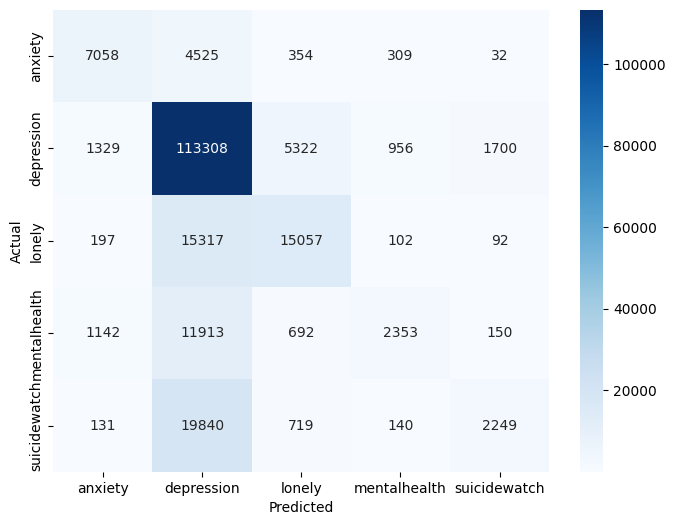

In [8]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Make predictions on the test data using the trained lgb_model
y_pred_lgb = lgb_model.predict(X_test_tfidf)

# 2. Print the evaluation report
print("\n--- LightGBM Classification Report ---")
print(classification_report(y_test, y_pred_lgb))

# Generate and plot the confusion matrix
print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred_lgb)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=lgb_model.classes_, yticklabels=lgb_model.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report

# 1. Initialize and train the MLP model
# This creates a network with one hidden layer of 100 neurons.
mlp_model = MLPClassifier(random_state=42, max_iter=300, hidden_layer_sizes=(100,))
mlp_model.fit(X_train_tfidf, y_train)

print("MLP (Neural Network) model trained successfully!")

# 2. Make predictions and evaluate
y_pred_mlp = mlp_model.predict(X_test_tfidf)

print("\n--- MLP Classifier Report ---")
print(classification_report(y_test, y_pred_mlp))

# Generate and plot the confusion matrix
print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred_mlp)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=model.classes_, yticklabels=model.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

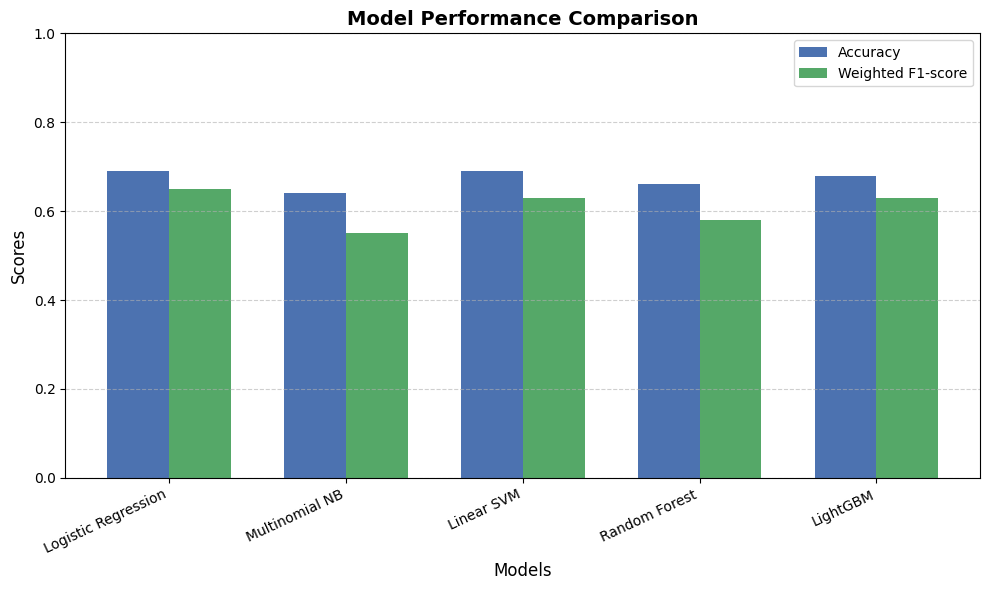

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# --- Model names ---
models = ['Logistic Regression', 'Multinomial NB', 'Linear SVM', 'Random Forest', 'LightGBM']

# --- Performance metrics ---
accuracy = [0.69, 0.64, 0.69, 0.66, 0.68]
f1_score = [0.65, 0.55, 0.63, 0.58, 0.63]

# --- Set up bar positions ---
x = np.arange(len(models))
width = 0.35  # width of each bar

# --- Create the plot ---
plt.figure(figsize=(10, 6))
plt.bar(x - width/2, accuracy, width, label='Accuracy', color='#4C72B0')
plt.bar(x + width/2, f1_score, width, label='Weighted F1-score', color='#55A868')

# --- Add labels, title, and grid ---
plt.xlabel('Models', fontsize=12)
plt.ylabel('Scores', fontsize=12)
plt.title('Model Performance Comparison', fontsize=14, fontweight='bold')
plt.xticks(x, models, rotation=25, ha='right')
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)

# --- Display the plot ---
plt.tight_layout()
plt.show()
